# Task map

Every policy's success on each of the 40 LIBERO tasks, tasks sorted from easiest to hardest (mean over policies): if the policies fail on the same tasks, the rows look alike.

In [1]:
import json
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

import utils as u

FS_SMALL, FS_TINY = 9, 7  # pt: \small, \scriptsize of the paper
PAGE_WIDTH = 5.5  # in: \textwidth of the paper (\linewidth of a figure)
ROOT = Path.cwd().parent
data_path = ROOT / "results"
figs_path = ROOT / "analysis/figs"
style_path = ROOT / "analysis/figure.mplstyle"

In [2]:
data = json.loads((data_path / "data.json").read_text())
figs_path.mkdir(exist_ok=True)
plt.style.use(style_path)

Failure overlap between the kNN and each VLA, and the per-task correlation (quoted in `numbers.tex`).

In [3]:
for bench in ("libero", "libero_plus"):
    print(bench, u.failure_overlap(data, bench))
    print(bench, u.task_corr(data, bench))

libero [('π0.5', 0.2608695652173913, 0.083), ('MolmoAct2', 0.4, 0.083), ('GR00T N1.7', 0.2524271844660194, 0.083), ('VLA-JEPA', 0.45614035087719296, 0.083), ('Evo-1', 0.3695652173913043, 0.083), ('X-VLA', 0.24545454545454545, 0.083), ('π0', 0.19715808170515098, 0.083), ('SmolVLA', 0.23249299719887956, 0.083), ('π0-FAST', 0.2222222222222222, 0.083)]
libero [0.7435856182035877, 0.651331950710731, 0.6739739440510174, 0.8270831165455106, 0.7728389866055401, 0.18314789854506458, 0.8043570167819133, 0.853338489056938, 0.5825731080490382]
libero_plus [('π0.5', 0.47540983606557374, 0.1761904761904762), ('MolmoAct2', 0.3835616438356164, 0.1761904761904762), ('GR00T N1.7', 0.4578313253012048, 0.1761904761904762), ('VLA-JEPA', 0.3577981651376147, 0.1761904761904762), ('Evo-1', 0.375, 0.1761904761904762), ('X-VLA', 0.2483221476510067, 0.1761904761904762), ('π0', 0.23333333333333334, 0.1761904761904762), ('SmolVLA', 0.20462046204620463, 0.1761904761904762), ('π0-FAST', 0.1955128205128205, 0.1761904

In [4]:
panels = [(bench, *u.task_matrix(data, bench)) for bench in ("libero", "libero_plus")]
n = len(u.POLICIES)
cmap = mpl.colors.LinearSegmentedColormap.from_list("succ", ["#ffffff", "#c9dcf4", "#5a9be3", "#104281"])

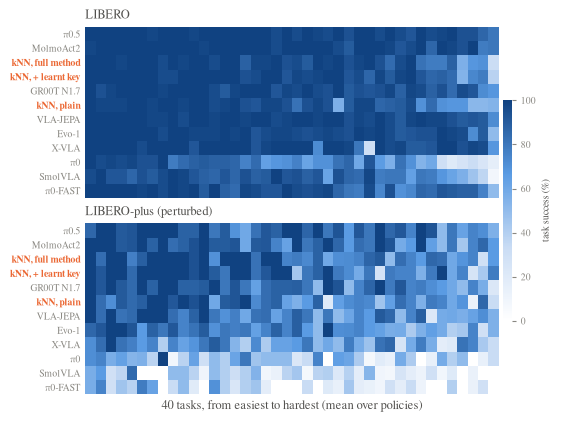

In [ ]:
fig, axes = plt.subplots(len(panels), 1, figsize=(PAGE_WIDTH, 0.432 + 0.1296 * n * len(panels) + 0.288 * len(panels)),
                         layout="constrained", squeeze=False)  # fmt: skip
axes = axes[:, 0]
for ax, (bench, rows, m) in zip(axes, panels, strict=True):
    ax.imshow(m, cmap=cmap, vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(rows)), [re.sub(r"π([\d.]+)", r"$\\pi_{\1}$", lab) for lab in rows], fontsize=FS_TINY)
    for tick, lab in zip(ax.get_yticklabels(), rows, strict=True):
        if lab.startswith("kNN"):
            tick.set_color(u.Colour.KNN)
            tick.set_fontweight("bold")
    ax.set_xticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title("LIBERO" if bench == "libero" else "LIBERO-plus (perturbed)", fontsize=FS_SMALL,
                 loc="left")  # fmt: skip
axes[-1].set_xlabel("40 tasks, from easiest to hardest (mean over policies)", fontsize=FS_SMALL)
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(0, 100))
cb = fig.colorbar(sm, ax=axes, location="right", shrink=0.6, pad=0.01, aspect=25)
cb.set_label("task success (%)", fontsize=FS_TINY)
cb.ax.tick_params(labelsize=FS_TINY)
cb.outline.set_visible(False)
fig.savefig(figs_path / "task_map.pdf")